In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_ROOT = Path("/Users/hongmo/Desktop/Gradient Boosting")

results = {
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost (Initial)",
        "LightGBM",
        "CatBoost",
        "XGBoost (Tuned)"
    ],
    "Training AUC": [
        0.7480, 0.7961, 0.7829,
        0.8183, 0.7704, None
    ],
    "Validation AUC": [
        0.7433, 0.7358, 0.7573,
        0.7582, 0.7561, 0.7605
    ],
    "Training Time (s)": [
        None, 30.36, None,
        7.67, 13.93, None
    ]
}

comparison_df = pd.DataFrame(results)

comparison_df["AUC Gap"] = (
    comparison_df["Training AUC"]
    - comparison_df["Validation AUC"]
)

comparison_df = comparison_df.sort_values(
    by="Validation AUC",
    ascending=False
)

display(comparison_df.round(4))

,Model,Training AUC,Validation AUC,Training Time (s),AUC Gap
5,XGBoost (Tuned),NaN,0.7605,NaN,NaN
3,LightGBM,0.8183,0.7582,7.67,0.0601
2,XGBoost (Initial),0.7829,0.7573,NaN,0.0256
4,CatBoost,0.7704,0.7561,13.93,0.0143
0,Logistic Regression,0.7480,0.7433,NaN,0.0047
1,Random Forest,0.7961,0.7358,30.36,0.0603


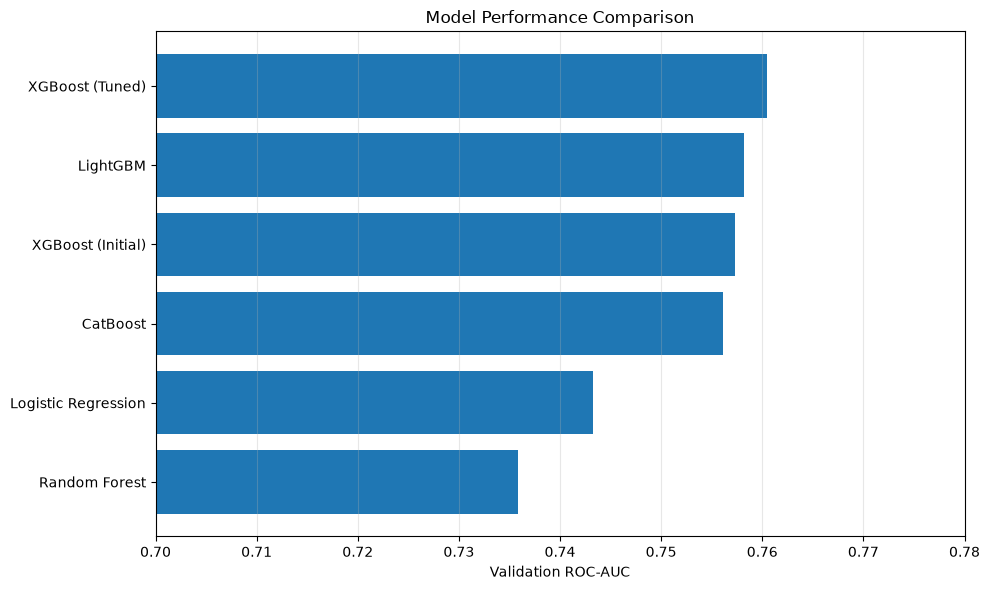

In [2]:
plt.figure(figsize=(10, 6))

plt.barh(
    comparison_df["Model"],
    comparison_df["Validation AUC"]
)

plt.xlabel("Validation ROC-AUC")
plt.title("Model Performance Comparison")
plt.xlim(0.70, 0.78)
plt.gca().invert_yaxis()

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

output_dir = PROJECT_ROOT / "outputs" / "figures"
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [3]:
comparison_df.to_csv(
    PROJECT_ROOT / "outputs" / "model_comparison.csv",
    index=False
)